<a href="https://colab.research.google.com/github/100522371/P2_AA_Grupo17/blob/main/p2_grupo17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Montserrat Martis Contreras - 100522371

Laith Basem Elbeshti - 100477240

In [1]:
import pandas as pd

df = pd.read_csv('stars_data.csv')
df.head()

,Temperature,L,R,A_M,Color,Spectral_Class
0,3068,0.002400,0.1700,16.12,Red,M
1,3042,0.000500,0.1542,16.60,Red,M
2,2600,0.000300,0.1020,18.70,Red,M
3,2800,0.000200,0.1600,16.65,Red,M
4,1939,0.000138,0.1030,20.06,Red,M


La codificación ordinal es una técnica de preparación de datos en aprendizaje automático que se utiliza para transformar variables categóricas en números enteros, basándose en que existe un orden o jerarquía natural entre esas categorías.

Sabemos que Spectral_Class tiene 7 posibles valores (O, B, A, F, G, K, M) que van desde lo mas frio a lo mas caliente. Esto lo podemos transformar a valores númericos del 0 al 6.

In [2]:
print(df['Spectral_Class'].unique())

['M' 'B' 'A' 'F' 'O' 'K' 'G']


En el documento solo aparecen tres colores principales rojo, amarillo y blanco.

---



In [3]:
print(df['Color'].unique())

['Red' 'Blue White' 'White' 'Yellowish White' 'Blue white'
 'Pale yellow orange' 'Blue' 'Blue-white' 'Whitish' 'yellow-white'
 'Orange' 'White-Yellow' 'white' 'yellowish' 'Yellowish' 'Orange-Red'
 'Blue-White']


Pero como podemos ver, hay más colores y algunos estan repetidos. Antes de codificarlos, vamos a arreglar esto

In [4]:
df['Color'] = df['Color'].str.lower()
def clean_color(color):
    if 'blue white' in color or 'blue-white' in color:
        return 'Blue-White'
    elif 'yellowish white' in color or 'white-yellow' in color or 'yellow-white' in color:
        return 'White-Yellow'
    elif 'pale yellow orange' in color:
        return 'Yellow-Orange'
    elif 'whitish' in color or 'white' in color:
        return 'White'
    elif 'yellowish' in color or 'yellow' in color:
        return 'Yellow'
    elif 'orange-red' in color:
        return 'Orange-Red'
    elif 'orange' in color:
        return 'Orange'
    elif 'red' in color:
        return 'Red'
    elif 'blue' in color:
        return 'Blue'
    else:
        return 'Other'

df['Color'] = df['Color'].apply(clean_color)
print(df['Color'].unique())

['Red' 'Blue-White' 'White' 'White-Yellow' 'Yellow-Orange' 'Blue' 'Orange'
 'Yellow' 'Orange-Red']


Ahora los colores reflejan una escala de temperatura, desde el más frío (Rojo) hasta el más caliente (Azul). Para mantener el orden de temperatura, se traducen a números del 0 al 8, donde los colores principales toman valores pares y los colores intermedios (como Orange-Red o Blue-White) toman los valores impares.

In [5]:
# Mapeo de la Clase Espectral de mas fria (M) a mas caliente (O)
spectral_mapping = {'M': 0, 'K': 1, 'G': 2, 'F': 3, 'A': 4, 'B': 5, 'O': 6}
df['Spectral_Class'] = df['Spectral_Class'].map(spectral_mapping)

# Mapeo de los colores basándonos en la temperatura (rojo es mas frio, azul es mas caliente)
color_mapping = {
    'Red': 0,
    'Orange-Red': 1,
    'Orange': 2,
    'Yellow-Orange': 3,
    'Yellow': 4,
    'White-Yellow': 5,
    'White': 6,
    'Blue-White': 7,
    'Blue': 8,
    'Other': 0 # Default para cualquier otro no identificado, asimilándolo a menor temperatura
}
df['Color'] = df['Color'].map(color_mapping)

df.head()

,Temperature,L,R,A_M,Color,Spectral_Class
0,3068,0.002400,0.1700,16.12,0,0
1,3042,0.000500,0.1542,16.60,0,0
2,2600,0.000300,0.1020,18.70,0,0
3,2800,0.000200,0.1600,16.65,0,0
4,1939,0.000138,0.1030,20.06,0,0


# PCA

En esta sección buscamos resumir la información de todas las columnas (6 variables) en solo dos nuevas variables o dimensiones (las componentes principales), perdiendo la menor cantidad de información o varianza posible.

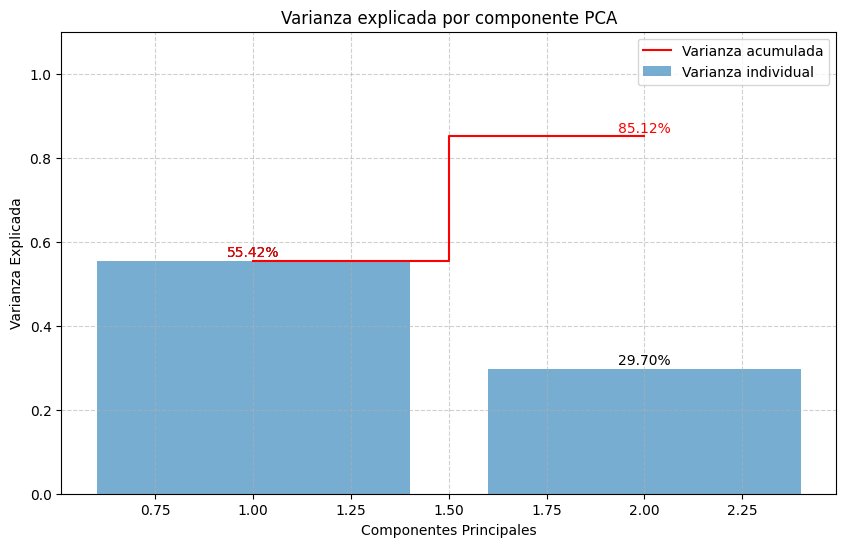

In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt
import numpy as np

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=2, random_state=100522371))
])

df_pca = pipeline.fit_transform(df)
# convertimos el df_pca en un dataframe que podemos manipular
df = pd.DataFrame(df_pca, columns=['PC1', 'PC2'])
pca = pipeline.named_steps['pca']

# Varianza explicada y acumulada
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Plot de Varianza Explicada y Acumulada
plt.figure(figsize=(10, 6))
plt.bar(range(1, len(explained_variance) + 1), explained_variance, alpha=0.6, label='Varianza individual')
plt.step(range(1, len(cumulative_variance) + 1), cumulative_variance, where='mid', label='Varianza acumulada', color='red')

# Añadir valores exactos
for i, (ev, cv) in enumerate(zip(explained_variance, cumulative_variance)):
    plt.text(i + 1, ev + 0.01, f"{ev:.2%}", ha='center')
    plt.text(i + 1, cv + 0.01, f"{cv:.2%}", ha='center', color='red')

plt.xlabel('Componentes Principales')
plt.ylabel('Varianza Explicada')
plt.title('Varianza explicada por componente PCA')
plt.legend(loc='best')
plt.ylim(0, 1.1)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

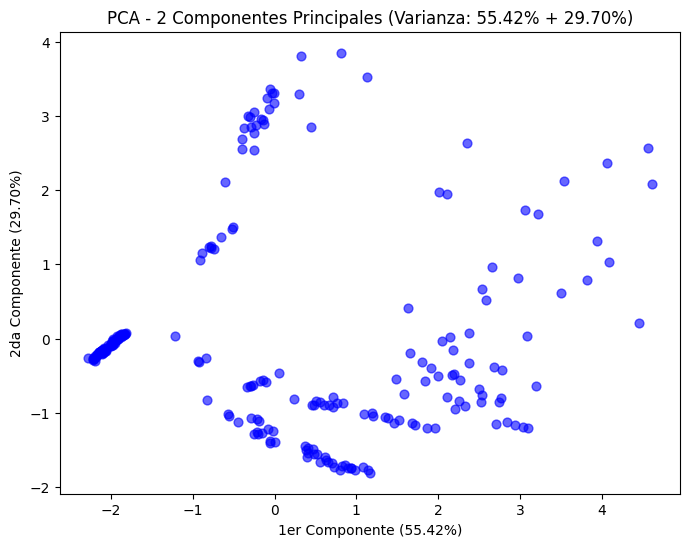

In [18]:
# Visualizar 2 componentes
# No tenemos un target como en el ejemplo, asi que hacemos un plot de color sólido
plt.figure(figsize=(8, 6))
plt.scatter(df_pca[:, 0], df_pca[:, 1], c='blue', s=40, alpha=0.6)
plt.title('PCA - 2 Componentes Principales (Varianza: {:.2%} + {:.2%})'.format(explained_variance[0], explained_variance[1]))
plt.xlabel('1er Componente ({:.2%})'.format(explained_variance[0]))
plt.ylabel('2da Componente ({:.2%})'.format(explained_variance[1]))
plt.show()

In [19]:
df.head()

,PC1,PC2
0,-2.076410,-0.141135
1,-2.095980,-0.158994
2,-2.197765,-0.229721
3,-2.109804,-0.155463
4,-2.282131,-0.267054
